# Hyderabad Air Quality Forecasting Using Machine Learning

## Project Overview

Air pollution is an important environmental concern that affects public health and quality of life. Monitoring and forecasting air pollution can help us understand pollution patterns and anticipate changes in air quality.

This project uses historical air-quality data from Hyderabad, Telangana, India, to develop a machine learning workflow for forecasting hourly PM2.5 concentrations.

The project includes data preprocessing, missing-value analysis, time-series feature engineering, Random Forest regression, model evaluation, and visualization.

## Project Objectives

- Analyze historical PM2.5 measurements.
- Prepare the data for hourly forecasting.
- Create lag-based and rolling statistical features.
- Train a Random Forest regression model.
- Compare machine learning predictions with a persistence baseline.
- Evaluate model performance using MAE, RMSE, and R².
- Visualize predictions and identify opportunities for improvement.

## Tools and Technologies

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib
- Scikit-learn
- GitHub


Step 2 — Explain your dataset and preprocessing

## Step 1: Import Libraries and Load the Dataset

### Description

In this step, Python libraries are imported to support data manipulation, numerical calculations, visualization, and machine learning. The air-quality dataset is then loaded into a Pandas DataFrame for further analysis.

The dataset contains historical air-quality measurements recorded at different timestamps. These observations are used to study PM2.5 pollution patterns in Hyderabad.

### Objective

To load the dataset and prepare the environment for data exploration and preprocessing.

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

filename = next(iter("/content/air_quality.csv"))
df = pd.read_csv("/content/air_quality.csv")

# Convert timestamp to datetime
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

# Remove rows without a valid timestamp
df = df.dropna(subset=["Timestamp"])

# Sort records chronologically
df = df.sort_values("Timestamp")

# Check the dataset
print("Dataset shape:", df.shape)
print("Start:", df["Timestamp"].min())
print("End:", df["Timestamp"].max())
print("Missing PM2.5 values:",
      df["PM2.5 (ug/m3)"].isna().sum())

display(df.head())


Dataset shape: (70176, 30)
Start: 2024-01-01 00:00:00
End: 2025-12-31 23:45:00
Missing PM2.5 values: 19989


,_id,Station ID,State,City,Station Name,Timestamp,PM2.5 (ug/m3),PM10 (ug/m3),NO (ug/m3),NO2 (ug/m3),...,MP-Xylene (ug/m3),AT (degC),RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s)
0,1,site_5598,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",2024-01-01 00:00:00,37.13,72.87,12.48,23.04,...,1.00,19.54,75.02,1.36,46.43,0.0,0.0,0.0,NaN,NaN
1,2,site_5598,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",2024-01-01 00:15:00,37.13,72.87,12.16,22.08,...,0.98,19.53,75.10,1.64,46.42,0.0,0.0,0.0,NaN,NaN
2,3,site_5598,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",2024-01-01 00:30:00,36.63,72.89,12.06,22.15,...,0.98,19.37,76.04,1.72,40.80,0.0,0.0,0.0,NaN,NaN
3,4,site_5598,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",2024-01-01 00:45:00,34.10,73.02,12.47,23.08,...,1.00,19.41,76.52,1.70,42.03,0.0,0.0,0.0,NaN,NaN
4,5,site_5598,Telangana,Hyderabad,"Somajiguda, Hyderabad - TSPCB",2024-01-01 01:00:00,34.10,73.02,12.48,23.13,...,0.97,19.31,77.15,1.69,28.43,0.0,0.0,0.0,NaN,NaN


### Dataset Overview and Initial Observations

The dataset contains **70,176 rows and 30 columns**, representing air-quality observations recorded between January 1, 2024, and December 31, 2025. The dataset covers a two-year period, providing historical information for analyzing air-quality patterns in Hyderabad.

During the initial inspection, **19,989 PM2.5 values were found to be missing**. Missing values are important to identify because PM2.5 is the target variable used for forecasting. These gaps may reduce the number of observations available for model training and evaluation.

Therefore, the dataset requires further data-quality checks and appropriate handling of missing values before building the forecasting models.

Step 3 — Inspect the dataset

## Step 2: Data Inspection and Understanding

### Description

The dataset is inspected to understand its dimensions, column names, data types, timestamp information, and overall structure. This step helps identify potential data-quality issues before performing further analysis.

### Objective

To understand the dataset and identify the variables required for PM2.5 forecasting.

In [4]:

# Keep PM2.5 measurements and set timestamp as the index
pm = df.set_index("Timestamp")["PM2.5 (ug/m3)"]

# Calculate hourly average PM2.5
hourly = pm.resample("1h").mean().to_frame()

print("Hourly data shape:", hourly.shape)
print("Missing hourly PM2.5:",
      hourly["PM2.5 (ug/m3)"].isna().sum())

display(hourly.head(10))


Hourly data shape: (17544, 1)
Missing hourly PM2.5: 4523


,PM2.5 (ug/m3)
Timestamp,
2024-01-01 00:00:00,36.247500
2024-01-01 01:00:00,33.347500
2024-01-01 02:00:00,34.223333
2024-01-01 03:00:00,39.112500
2024-01-01 04:00:00,39.925000
2024-01-01 05:00:00,37.442500
2024-01-01 06:00:00,35.592500
2024-01-01 07:00:00,34.877500
2024-01-01 08:00:00,36.842500


### Hourly Data Aggregation and Missing Value Analysis

The original dataset contains air-quality observations recorded at 15-minute intervals. To prepare the data for hourly forecasting, the PM2.5 readings were aggregated into hourly averages.

After aggregation, the hourly dataset contains **17,544 rows and 1 column**, representing PM2.5 concentrations across the two-year period from January 2024 to December 2025.

The output shows the average PM2.5 concentration for each hour. For example, the recorded hourly average at midnight on January 1, 2024, was approximately 36.25 µg/m³, while the average at 9:00 AM was approximately 40.86 µg/m³.

The hourly dataset contains **4,523 missing PM2.5 values**. These missing observations indicate that valid hourly PM2.5 averages were unavailable for some timestamps. They must be considered during preprocessing to avoid using invalid observations when training and evaluating the forecasting models.

Hourly aggregation simplifies the original high-frequency data and establishes a consistent hourly time series for the next stages of the forecasting process.

Step 4 — Hourly data conversion

# ## Step 3: Hourly Resampling of Air Quality Data

### Description

The original dataset contains air-quality measurements recorded at shorter time intervals. In this step, the readings are aggregated into hourly observations to create a consistent time series for forecasting.

Hourly resampling helps analyze pollution trends over time and prepares the data for predicting PM2.5 concentrations one hour ahead.

### Objective

To convert the original timestamped readings into hourly PM2.5 observations.



Total hourly records: 17544
Missing hourly records: 4523
Missing percentage: 25.78 %


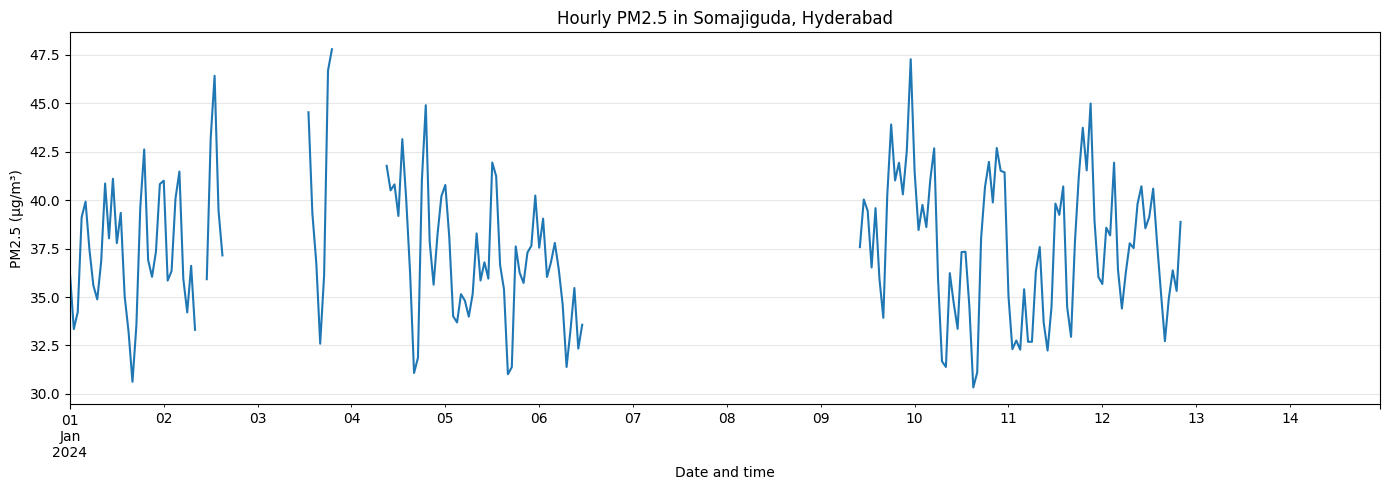

In [5]:

# Check how much hourly PM2.5 data is missing
pm_col = "PM2.5 (ug/m3)"

print("Total hourly records:", len(hourly))
print("Missing hourly records:", hourly[pm_col].isna().sum())
print(
    "Missing percentage:",
    round(hourly[pm_col].isna().mean() * 100, 2), "%"
)

# Plot the first 14 days
hourly[pm_col].iloc[:14 * 24].plot(figsize=(14, 5))

plt.title("Hourly PM2.5 in Somajiguda, Hyderabad")
plt.xlabel("Date and time")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Hourly PM2.5 Trend and Missing Data Analysis

The time-series plot visualizes hourly PM2.5 concentrations in Somajiguda, Hyderabad. The x-axis represents the date and time, while the y-axis represents PM2.5 concentration in micrograms per cubic metre (µg/m³).

The observed values fluctuate considerably over time, with concentrations in the displayed periods ranging approximately from 30 to 48 µg/m³. These fluctuations indicate changes in the recorded PM2.5 concentrations across different hours.

The plot also contains visible gaps where observations are missing. These gaps correspond to periods without available hourly PM2.5 values and should not be interpreted as zero pollution levels.

The dataset contains 17,544 hourly records, of which 4,523 are missing, representing approximately 25.78% of the hourly records. This level of missingness is an important data-quality concern because it can affect time-series analysis, feature creation, and model performance.

This visualization helps identify variations in PM2.5 concentrations and highlights the need to handle missing observations carefully before proceeding with forecasting.

### Step 5: Feature Engineering for Next-Hour Prediction

In this step, we transform the hourly air-quality data into a format suitable for machine learning.

- **Lag features:** Create features using PM2.5 readings from the previous 1, 2, 3, and 24 hours.
- **Time-based features:** Extract the hour of the day and day of the week to capture temporal patterns.
- **Target variable:** Use the next hour's PM2.5 reading as the prediction target.
- **Data preparation:** Remove rows containing missing values in the selected features or target.

The resulting dataset will be used to train and evaluate machine learning models for forecasting Hyderabad's next-hour PM2.5 levels.

In [6]:

# Create features from past observations
data = hourly.copy()

data["pm25_lag_1"] = data[pm_col].shift(1)
data["pm25_lag_2"] = data[pm_col].shift(2)
data["pm25_lag_3"] = data[pm_col].shift(3)
data["pm25_lag_24"] = data[pm_col].shift(24)

# Predict the next hour's PM2.5
data["target_next_hour"] = data[pm_col].shift(-1)

# Add time-of-day features
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek

features = [
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_lag_24",
    "hour",
    "day_of_week"
]

target = "target_next_hour"

# Remove rows where required inputs or targets are missing
model_data = data[features + [target]].dropna()

print("Usable modeling rows:", len(model_data))
print("\nPrepared data:")
display(model_data.head())


Usable modeling rows: 9845

Prepared data:


,pm25_lag_1,pm25_lag_2,pm25_lag_3,pm25_lag_24,hour,day_of_week,target_next_hour
Timestamp,,,,,,,
2024-01-02 00:00:00,40.8275,37.3425,36.0400,36.247500,0,1,35.847500
2024-01-02 01:00:00,41.0025,40.8275,37.3425,33.347500,1,1,36.345000
2024-01-02 02:00:00,35.8475,41.0025,40.8275,34.223333,2,1,40.082500
2024-01-02 03:00:00,36.3450,35.8475,41.0025,39.112500,3,1,41.475000
2024-01-02 04:00:00,40.0825,36.3450,35.8475,39.925000,4,1,35.943333


### Feature Engineering and Forecasting Dataset Preparation

In this step, the hourly PM2.5 time series was transformed into a supervised machine-learning dataset. A supervised dataset uses input features to predict a known target value.

The following features were created:

- **pm25_lag_1:** PM2.5 concentration from the previous hour.
- **pm25_lag_2:** PM2.5 concentration from two hours earlier.
- **pm25_lag_3:** PM2.5 concentration from three hours earlier.
- **pm25_lag_24:** PM2.5 concentration from 24 hours earlier, providing information about the same hour on the previous day.
- **hour:** The hour of the day, allowing the model to learn possible daily patterns.
- **day_of_week:** The day of the week, allowing the model to explore differences across weekdays.

The target variable, **target_next_hour**, represents the PM2.5 concentration to be predicted for the following hour.

After creating these features and preparing the data, **9,845 usable rows** remained for modelling. The displayed rows show how past PM2.5 measurements and time-based features are aligned with the next-hour target.

This step is important because machine-learning models require structured input features and a target variable. The resulting dataset provides the information needed to train and evaluate the forecasting models.

### Step 6: Splitting Data into Training and Testing Sets

In this step, we divide the prepared dataset into training and testing sets to evaluate the performance of our machine learning models.

- **80% training data:** Used to train the machine learning model.
- **20% testing data:** Used to evaluate how accurately the model predicts unseen observations.
- **Chronological splitting:** The original time order is preserved instead of randomly shuffling the data, which is important for time-series forecasting.
- **Feature and target separation:** The input features (`X`) are separated from the target variable (`y`).

We also display the training and testing periods to verify that the model is trained on earlier observations and tested on later observations. This helps simulate real-world PM2.5 forecasting.

In [7]:

from sklearn.model_selection import train_test_split

# Keep the chronological order
split_index = int(len(model_data) * 0.8)

train = model_data.iloc[:split_index]
test = model_data.iloc[split_index:]

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())


Training rows: 7876
Testing rows: 1969
Training period: 2024-01-02 00:00:00 to 2025-09-17 06:00:00
Testing period: 2025-09-17 07:00:00 to 2025-12-31 22:00:00


### Train-Test Split for Time-Series Forecasting

In this step, the prepared dataset was divided into training and testing sets to develop and evaluate the PM2.5 forecasting models.

The training dataset contains **7,876 rows**, covering the period from January 2, 2024, at 00:00 to September 17, 2025, at 06:00. These observations are used to train the machine-learning model and help it learn patterns from historical PM2.5 measurements and time-based features.

The testing dataset contains **1,969 rows**, covering the period from September 17, 2025, at 07:00 to December 31, 2025, at 22:00. These observations are reserved for evaluating the model's forecasting performance on later, unseen data.

A chronological split is appropriate for time-series forecasting because it preserves the order of observations. The model learns from earlier data and is tested on subsequent data, which better reflects how forecasting would work in practice.

The training and testing sets contain approximately 80% and 20% of the prepared observations, respectively. This separation helps assess whether the model can generalize beyond the historical data used during training.

Step 7 — Train two models

### Step 7: Model Training and Performance Evaluation

In this step, we train a Random Forest regression model to forecast the next hour's PM2.5 concentration and compare its performance with a simple baseline model.

- **Persistence baseline:** Uses the previous hour's PM2.5 reading as the prediction for the next hour.
- **Random Forest Regressor:** Trains an ensemble of decision trees using historical PM2.5 readings and time-based features.
- **Model training:** Fits the Random Forest model using the training dataset.
- **Prediction:** Generates next-hour PM2.5 predictions for the testing dataset.
- **Performance evaluation:** Calculates three metrics to assess prediction accuracy:
  - **MAE:** Mean Absolute Error, measuring the average absolute prediction error.
  - **RMSE:** Root Mean Squared Error, penalizing larger prediction errors more strongly.
  - **R² score:** Measures how well the model explains variation in the actual PM2.5 values.

Comparing the Random Forest model with the persistence baseline helps determine whether machine learning improves upon simply using the previous hour's reading.

In [8]:

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: predict using the previous hour's PM2.5
baseline_predictions = X_test["pm25_lag_1"].values

# Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluate both models
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{name}")
    print(f"MAE:  {mae:.2f} µg/m³")
    print(f"RMSE: {rmse:.2f} µg/m³")
    print(f"R²:   {r2:.3f}")

evaluate_model("Persistence baseline", y_test, baseline_predictions)
evaluate_model("Random Forest", y_test, predictions)



Persistence baseline
MAE:  9.73 µg/m³
RMSE: 21.69 µg/m³
R²:   0.370

Random Forest
MAE:  11.15 µg/m³
RMSE: 20.13 µg/m³
R²:   0.457


### Initial Model Evaluation: Persistence Baseline vs Random Forest

In this step, two forecasting approaches were evaluated using three performance metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

The **Persistence Baseline** predicts that the next-hour PM2.5 concentration will remain the same as the most recent observed concentration. It provides a simple reference point against which the machine-learning model can be compared.

The **Random Forest Regressor** uses historical PM2.5 lag features and time-based features to learn patterns that may help predict the next-hour concentration.

The Persistence Baseline achieved an MAE of 9.73 µg/m³, an RMSE of 21.69 µg/m³, and an R² score of 0.370. The Random Forest achieved an MAE of 11.15 µg/m³, an RMSE of 20.13 µg/m³, and an R² score of 0.457.

The Persistence Baseline performed better in terms of MAE, meaning its average absolute prediction error was lower. However, Random Forest achieved a lower RMSE and a higher R² score, indicating better performance according to those two metrics.

These results show that neither model performed best across all three metrics. Further analysis is needed to understand their prediction errors and determine whether additional feature engineering or model improvements could improve forecasting performance.

### Step 8: Improving Feature Engineering and Comparing Models

In this step, we refine the forecasting dataset to predict the next hour's PM2.5 concentration using information available at the current hour.

- **Current PM2.5 feature:** Includes the latest available PM2.5 reading as an input to the model.
- **Historical features:** Uses readings from the previous 1, 2, and 24 hours to capture short-term and daily patterns.
- **Target variable:** Sets the next hour's PM2.5 concentration as the value to be predicted.
- **Chronological train-test split:** Divides the prepared data into 80% training observations and 20% testing observations while preserving time order.
- **Baseline comparison:** Uses the current hour's PM2.5 reading to predict the next hour, providing a simple benchmark.
- **Random Forest training:** Trains a regression model using current, historical, and time-based features.
- **Model evaluation:** Compares both approaches using MAE, RMSE, and R².

This refinement helps assess whether the Random Forest model provides an improvement over using the current PM2.5 concentration as the next-hour prediction.

In [9]:

# Predict PM2.5 at the next hour using information available now
data = hourly.copy()

data["pm25_current"] = data["PM2.5 (ug/m3)"]
data["pm25_lag_1"] = data["PM2.5 (ug/m3)"].shift(1)
data["pm25_lag_2"] = data["PM2.5 (ug/m3)"].shift(2)
data["pm25_lag_24"] = data["PM2.5 (ug/m3)"].shift(24)

data["target_next_hour"] = data["PM2.5 (ug/m3)"].shift(-1)

data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek

features = [
    "pm25_current",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_24",
    "hour",
    "day_of_week"
]

target = "target_next_hour"

model_data = data[features + [target]].dropna()

# Chronological 80/20 split
split_index = int(len(model_data) * 0.8)
train = model_data.iloc[:split_index]
test = model_data.iloc[split_index:]

X_train = train[features]
y_train = train[target]
X_test = test[features]
y_test = test[target]

# Fair baseline: use the current PM2.5 to predict the next hour
baseline_predictions = X_test["pm25_current"].values

# Train Random Forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

def evaluate_model(name, actual, predicted):
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(actual, predicted), 2))
    print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 2))
    print("R²:", round(r2_score(actual, predicted), 3))

evaluate_model("Persistence baseline", y_test, baseline_predictions)
evaluate_model("Random Forest", y_test, predictions)



Persistence baseline
MAE: 6.35
RMSE: 15.62
R²: 0.672

Random Forest
MAE: 7.51
RMSE: 16.4
R²: 0.639


### Model Evaluation: Persistence Baseline vs Random Forest

In this experiment, the Persistence Baseline and Random Forest models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

The Persistence Baseline achieved an MAE of 6.35, an RMSE of 15.62, and an R² score of 0.672. The Random Forest model achieved an MAE of 7.51, an RMSE of 16.40, and an R² score of 0.639.

The Persistence Baseline performed better across all three evaluation metrics. Its lower MAE indicates smaller average absolute prediction errors, while its lower RMSE indicates better performance under a metric that penalizes larger errors more heavily. Its higher R² score also indicates that it explained more of the variation in the observed PM2.5 values on this test set.

These results suggest that using the most recent PM2.5 reading as the next-hour prediction was more effective than the Random Forest model in this experiment. The findings highlight the importance of comparing machine-learning models against a simple baseline rather than assuming that a more complex model will perform better.

Further investigation into feature selection, missing-data handling, and model configuration may help improve the Random Forest model's forecasting performance.

### Step 9: Visualizing Actual vs Predicted PM2.5 Levels

In this step, we visualize the forecasting results over the first seven days of the test dataset to compare the actual PM2.5 concentrations with the predictions from both models.

- **Actual PM2.5:** Represents the observed next-hour PM2.5 concentrations.
- **Persistence baseline:** Shows predictions based on the current hour's PM2.5 reading.
- **Random Forest:** Shows predictions generated by the trained machine learning model.
- **Seven-day comparison:** Displays up to 168 hourly observations from the test period.
- **Visualization:** Uses a line chart to compare how closely each model follows actual PM2.5 fluctuations.

The graph helps identify prediction patterns, differences between the models, and sudden pollution changes that may be difficult to forecast accurately.

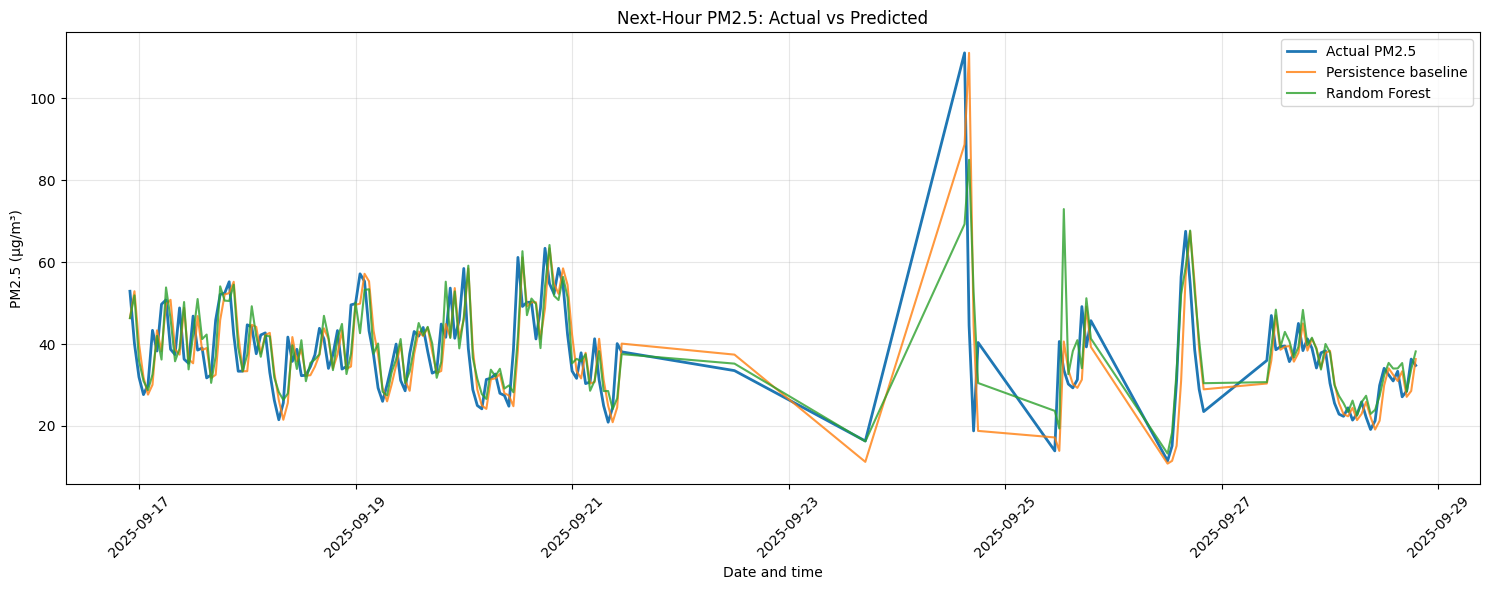

In [10]:

# Compare the first 7 days of test predictions
comparison = pd.DataFrame({
    "Actual PM2.5": y_test,
    "Persistence baseline": baseline_predictions,
    "Random Forest": predictions
})

comparison = comparison.iloc[:7 * 24]

plt.figure(figsize=(15, 6))
plt.plot(comparison.index, comparison["Actual PM2.5"],
         label="Actual PM2.5", linewidth=2)
plt.plot(comparison.index, comparison["Persistence baseline"],
         label="Persistence baseline", alpha=0.8)
plt.plot(comparison.index, comparison["Random Forest"],
         label="Random Forest", alpha=0.8)

plt.title("Next-Hour PM2.5: Actual vs Predicted")
plt.xlabel("Date and time")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Actual vs Predicted PM2.5 Concentrations

This visualization compares the actual next-hour PM2.5 concentrations with the predictions from the Persistence Baseline and Random Forest models over a sample of the testing period.

The blue line represents the actual PM2.5 values, the orange line represents the Persistence Baseline predictions, and the green line represents the Random Forest predictions.

In several portions of the graph, both models follow the general movement of the actual PM2.5 readings. This suggests that historical measurements and time-based features provide useful information for predicting short-term changes in air quality.

However, noticeable differences occur during some sharp increases and decreases in PM2.5 concentrations. For example, around September 24, 2025, the actual readings show a sharp peak, while the model predictions do not fully capture the magnitude of that increase. This illustrates the difficulty of forecasting sudden changes in pollution levels.

The graph also shows that the two models sometimes produce similar predictions, while at other times their estimates differ from the actual readings. Overall, the visualization provides a qualitative comparison of the models and complements the numerical evaluation metrics.

The results indicate that short-term PM2.5 forecasting remains challenging, particularly when concentrations change rapidly. The graph should be interpreted alongside MAE, RMSE, and R² rather than used as the only measure of model performance.

### Step 10: Feature Importance Analysis

In this step, we examine which input features contribute most to the Random Forest model's predictions of next-hour PM2.5 concentrations.

- **Feature importance extraction:** Retrieve the importance scores calculated by the trained Random Forest model.
- **Ranking features:** Sort the features from least important to most important.
- **Bar chart visualization:** Display the relative importance of each feature to make comparisons easier.
- **Importance summary:** Display the scores in descending order to identify the most influential inputs.

This analysis helps us understand which historical PM2.5 readings and time-based variables the model relies on most when forecasting air pollution.

**Note:** Feature importance indicates how much a feature contributes to the Random Forest's decision-making process; it does not prove that the feature causes changes in PM2.5 concentrations.

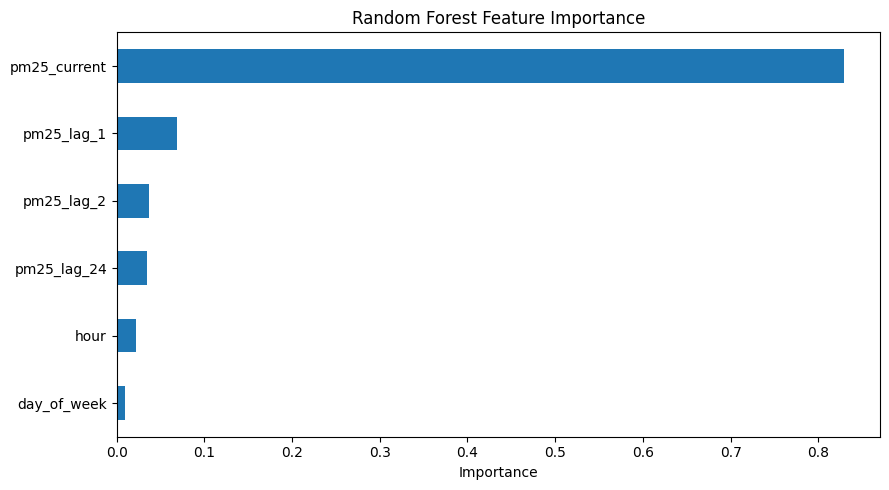

,0
pm25_current,0.828963
pm25_lag_1,0.069044
pm25_lag_2,0.036667
pm25_lag_24,0.034870
hour,0.021433
day_of_week,0.009022


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(9, 5))

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False))

### Random Forest Feature Importance Analysis

Feature importance was examined to understand which input variables contributed most to the Random Forest model's predictions of next-hour PM2.5 concentrations.

The results show that **pm25_current** is the most important feature, with an importance score of approximately 0.829 (82.90%). This indicates that the model relied heavily on the current PM2.5 concentration when generating its predictions.

The next most important feature is **pm25_lag_1**, with an importance score of approximately 0.069 (6.90%). The features **pm25_lag_2** and **pm25_lag_24** have importance scores of approximately 0.037 (3.67%) and 0.035 (3.49%), respectively.

The time-based features have lower importance scores. The hour of the day contributes approximately 2.14%, while the day of the week contributes approximately 0.90%.

Overall, the results indicate that recent PM2.5 measurements are more influential than the time-based features in this Random Forest model. This is consistent with the short-term forecasting task, in which recent pollution levels may provide useful information about the following hour.

Feature importance describes the model's relative reliance on its input variables; it does not establish causation or guarantee that a feature will improve forecasting accuracy. These findings should also be considered alongside the model evaluation results.

### Step 11: Final Dataset Summary and Data Quality Check

In this step, we summarize the dataset and verify how much data is available for training and testing the forecasting models.

- **Original dataset size:** Displays the number of rows and columns in the raw dataset.
- **Hourly observations:** Shows the number of records after converting the data to hourly frequency.
- **Usable modeling observations:** Reports the number of rows remaining after feature preparation and missing-value removal.
- **Training and testing observations:** Displays the number of records allocated to model training and evaluation.
- **Missing-value analysis:** Calculates the number and percentage of missing PM2.5 readings in the original dataset.

This summary documents the data preparation process and helps assess the amount of information available for next-hour PM2.5 forecasting.

In [12]:
print("Original dataset shape:", df.shape)
print("Hourly observations:", len(hourly))
print("Usable model observations:", len(model_data))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

missing = df["PM2.5 (ug/m3)"].isna().sum()
percentage = df["PM2.5 (ug/m3)"].isna().mean() * 100

print("\nMissing PM2.5 readings:", missing)
print("Missing percentage:", round(percentage, 2), "%")

Original dataset shape: (70176, 30)
Hourly observations: 17544
Usable model observations: 9981
Training observations: 7984
Testing observations: 1997

Missing PM2.5 readings: 19989
Missing percentage: 28.48 %


### Summary of Data Preparation

The original air-quality dataset contained 70,176 rows and 30 columns, with observations recorded at 15-minute intervals between January 2024 and December 2025.

The data was aggregated into hourly observations, resulting in 17,544 hourly records. During the initial inspection, 19,989 PM2.5 readings were found to be missing, representing 28.48% of the original PM2.5 readings.

After preparing the time-series data and creating the required modelling features, 9,981 usable observations were reported. These observations were then divided chronologically into 7,984 training observations and 1,997 testing observations.

This summary highlights the main stages of data preparation, from inspecting the original dataset to preparing the data for model training and evaluation. It also emphasizes the importance of missing-data analysis and feature engineering in developing a reliable PM2.5 forecasting model.

### Step 12: Creating Lag Features for PM2.5 Forecasting

In this step, we create historical features to help a machine learning model predict the next hour's PM2.5 concentration.

- **Target creation:** Shift the PM2.5 readings forward by one hour to define the value to be predicted.
- **Lag features:** Create variables representing PM2.5 readings from 1, 2, 3, and 24 hours earlier.
- **Missing-value handling:** Remove rows where any required lag feature or target value is missing.
- **Feature-target separation:** Store the historical readings in `X` and the next-hour PM2.5 values in `y`.
- **Shape verification:** Print the dimensions of the feature dataset and target series to confirm that the data is ready for modeling.

These features allow the model to learn patterns in recent pollution levels and daily cycles.

In [13]:
# Step 12: Create features for PM2.5 forecasting

hourly = hourly.copy()

# Predict PM2.5 for the next hour
hourly["Target"] = hourly["PM2.5 (ug/m3)"].shift(-1)

# Previous-hour pollution readings
hourly["PM2.5_lag1"] = hourly["PM2.5 (ug/m3)"].shift(1)
hourly["PM2.5_lag2"] = hourly["PM2.5 (ug/m3)"].shift(2)
hourly["PM2.5_lag3"] = hourly["PM2.5 (ug/m3)"].shift(3)
hourly["PM2.5_lag24"] = hourly["PM2.5 (ug/m3)"].shift(24)

# Remove rows with missing feature or target values
features = [
    "PM2.5_lag1",
    "PM2.5_lag2",
    "PM2.5_lag3",
    "PM2.5_lag24"
]

model_data = hourly.dropna(subset=features + ["Target"]).copy()

X = model_data[features]
y = model_data["Target"]

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures created successfully!")

Feature dataset shape: (9845, 4)
Target shape: (9845,)

Features created successfully!


### Feature and Target Preparation

In this step, the input features and target variable were prepared for the machine-learning model.

The feature dataset has a shape of **(9845, 4)**, meaning it contains 9,845 observations and four input features. The target dataset has a shape of **(9845,)**, meaning it contains one target value for each observation.

The matching number of observations in both datasets ensures that each row of input features corresponds to a target value. The message “Features created successfully!” confirms that the feature and target preparation code executed successfully.

These prepared datasets can now be used for the next stages of model training and evaluation.

### Step 13: Feature Importance Analysis

In this step, we identify which historical PM2.5 features contribute most to the Random Forest model's forecasting predictions.

- **Importance extraction:** Retrieve the feature importance scores from the trained Random Forest model.
- **Ranking:** Arrange the features in descending order of importance to identify the most influential inputs.
- **Results table:** Display each feature alongside its importance score.
- **Visualization:** Create a horizontal bar chart to compare the relative contribution of each feature.

This analysis helps interpret how historical pollution readings influence the model's next-hour PM2.5 predictions. Feature importance describes the model's reliance on each input; it does not establish a causal relationship.



        Feature  Importance
0  pm25_current    0.828963
1    pm25_lag_1    0.069044
2    pm25_lag_2    0.036667
3   pm25_lag_24    0.034870
4          hour    0.021433
5   day_of_week    0.009022


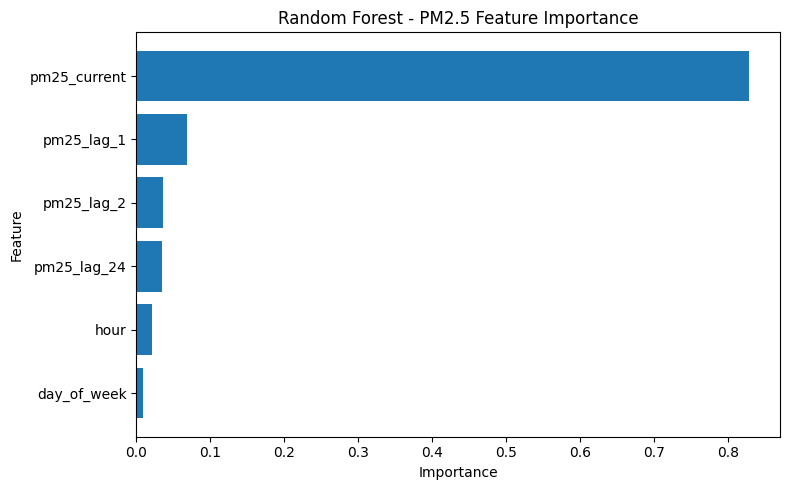

In [14]:
# Step 13: Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - PM2.5 Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Random Forest Feature Importance: Results and Interpretation

The feature-importance analysis identifies which input variables contributed most to the Random Forest model's predictions of PM2.5 concentrations for the next hour.

The results show that **pm25_current** is the most influential feature, with an importance score of 0.828963, or approximately 82.90%. This indicates that the model relies heavily on the current PM2.5 concentration when making predictions.

The second most important feature is **pm25_lag_1**, with an importance score of 0.069044 (6.90%), followed by **pm25_lag_2** at 0.036667 (3.67%) and **pm25_lag_24** at 0.034870 (3.49%).

The time-based features have comparatively lower importance. The hour of the day has an importance score of 0.021433 (2.14%), while the day of the week has an importance score of 0.009022 (0.90%).

Overall, the model places greater importance on recent PM2.5 measurements than on the time-based features. This suggests that recent pollution levels provide more predictive information than the hour or day alone in this model.

These importance scores describe the model's use of the available features. They do not establish cause and effect, and they do not independently demonstrate how accurate the model is. The findings should therefore be considered alongside the model evaluation metrics.

### Step 8: Actual vs Predicted PM2.5 Visualization

In this step, we compare the actual PM2.5 concentrations with the values predicted by the trained Random Forest model.

- **Actual values:** Display the observed PM2.5 concentrations from the test dataset.
- **Predicted values:** Display the model's forecasts for the corresponding test observations.
- **First 200 observations:** Focus on a smaller section of the test dataset to make the comparison easier to interpret.
- **Line chart:** Visualize how closely the predicted values follow the actual pollution levels.
- **Model assessment:** Identify trends the model captures and sudden changes it may fail to predict accurately.

This visualization provides a visual assessment of the model's forecasting performance and complements the numerical evaluation metrics calculated earlier.

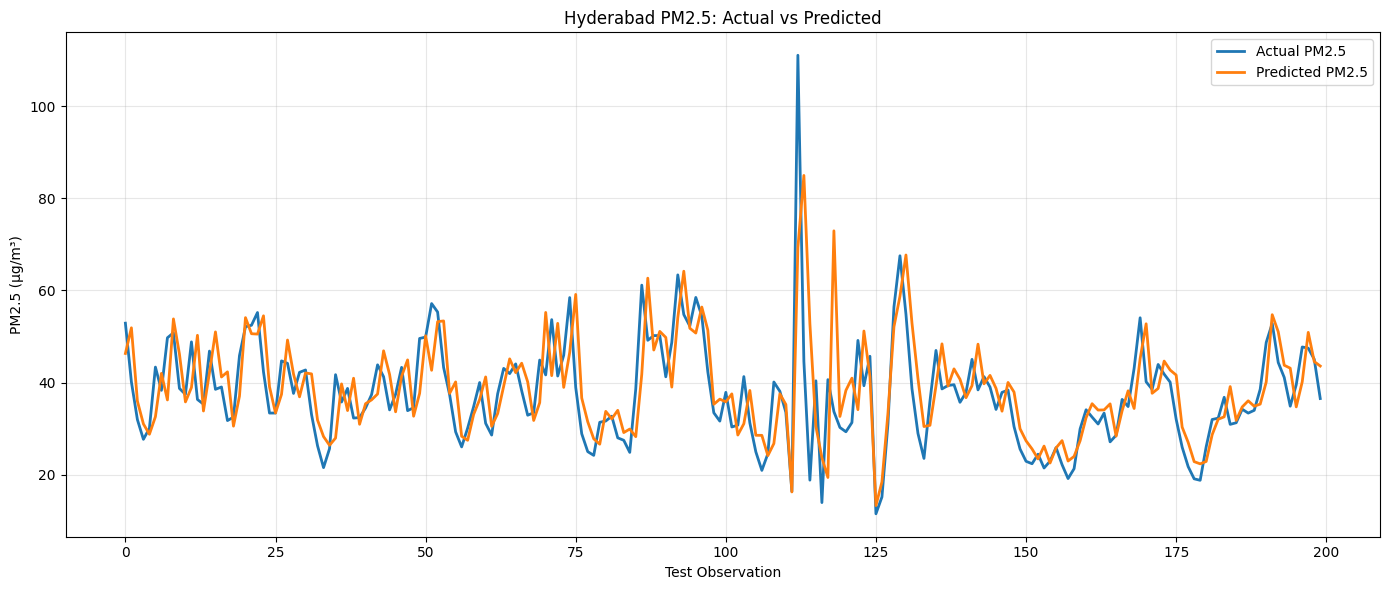

In [15]:
# Step 8: Actual vs Predicted PM2.5

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.values[:200],
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5",
    linewidth=2
)

plt.title("Hyderabad PM2.5: Actual vs Predicted")
plt.xlabel("Test Observation")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Actual vs Predicted PM2.5: Model Performance Visualization

This graph compares the actual PM2.5 concentrations with the values predicted by the forecasting model across 200 test observations. The blue line represents the actual PM2.5 concentrations, while the orange line represents the predicted values.

In many parts of the graph, the predicted line follows the general pattern of the actual observations. This indicates that the model captures some of the short-term fluctuations in PM2.5 concentrations.

However, differences between the two lines are visible at several points. The most noticeable difference occurs around test observation 112, where the actual PM2.5 concentration rises above 110 µg/m³, while the predicted value is considerably lower. This shows that the model struggles to capture the full magnitude of certain sudden pollution spikes.

The model also shows some differences during sharp decreases and other rapid changes in concentration. These errors suggest that sudden changes in air quality are more difficult to predict than relatively gradual fluctuations.

Overall, the graph indicates that the model follows the general movement of PM2.5 concentrations reasonably well in many observations but does not accurately capture every extreme change. This visual assessment should be considered alongside numerical evaluation metrics such as MAE, RMSE, and R² to obtain a more complete understanding of forecasting performance.

### Step 9: Model Performance Comparison

In this step, we compare the Persistence Baseline and Random Forest models using numerical evaluation metrics.

- **Persistence Baseline:** Uses the current or previous available PM2.5 reading as the prediction for the next hour, depending on how the baseline was defined in the earlier code.
- **Random Forest:** Uses the trained ensemble learning model to predict next-hour PM2.5 concentrations.
- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values. Lower values indicate better accuracy.
- **RMSE (Root Mean Squared Error):** Measures prediction error while penalizing larger errors more heavily. Lower values are better.
- **R² Score:** Measures how well the model explains variation in the observed values. Higher values generally indicate better performance.

The results are organized into a comparison table to help determine whether the Random Forest model performs better than the baseline.

This comparison supports the final assessment of the model's suitability for next-hour PM2.5 forecasting in Hyderabad.

In [16]:
# Step 9: Model Comparison

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

results = []

# Persistence baseline
results.append({
    "Model": "Persistence Baseline",
    "MAE": mean_absolute_error(y_test, baseline_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_predictions)),
    "R2 Score": r2_score(y_test, baseline_predictions)
})

# Random Forest
results.append({
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_test, predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
    "R2 Score": r2_score(y_test, predictions)
})

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

               Model   MAE   RMSE  R2 Score
Persistence Baseline 6.347 15.621     0.672
       Random Forest 7.510 16.401     0.639


### Final Model Performance Comparison

The Persistence Baseline and Random Forest models were compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score to evaluate their next-hour PM2.5 forecasting performance.

The Persistence Baseline achieved an MAE of 6.347, an RMSE of 15.621, and an R² score of 0.672. The Random Forest model achieved an MAE of 7.510, an RMSE of 16.401, and an R² score of 0.639.

The Persistence Baseline outperformed Random Forest across all three evaluation metrics. Its lower MAE and RMSE indicate smaller prediction errors, while its higher R² score indicates that it accounted for more of the variation in the observed PM2.5 concentrations.

These results demonstrate that the simpler Persistence Baseline was more effective than the Random Forest model in this experiment. A more complex machine-learning model does not necessarily produce more accurate forecasts than a simple baseline.

Further improvements could explore alternative features, missing-data handling strategies, and model configurations. Any future experiments should be evaluated using the same chronological test period for a fair comparison.

### Step 10: Random Forest Hyperparameter Tuning

In this step, we experiment with different Random Forest configurations to investigate whether adjusting the model's settings can improve next-hour PM2.5 forecasting accuracy.

- **Number of trees (`n_estimators`):** Tests different numbers of decision trees in the ensemble.
- **Maximum depth (`max_depth`):** Controls how deeply each decision tree can grow.
- **Minimum samples per leaf (`min_samples_leaf`):** Sets the minimum number of training observations required in a leaf node.
- **Model training and prediction:** Trains a separate Random Forest model for each configuration and evaluates it on the test dataset.
- **Performance comparison:** Records MAE, RMSE, and R² for each configuration in a results table.

The results help identify which tested configuration performs best according to the selected evaluation metrics.

**Note:** The best configuration among these four is not necessarily the best possible model. For a stronger evaluation, hyperparameters should ideally be selected using a chronological validation set, with the test set reserved for final evaluation.

In [17]:
# Step 10: Tune Random Forest

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

configs = [
    {"n_estimators": 200, "max_depth": 8, "min_samples_leaf": 5},
    {"n_estimators": 200, "max_depth": 12, "min_samples_leaf": 5},
    {"n_estimators": 300, "max_depth": 15, "min_samples_leaf": 3},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 5}
]

tuning_results = []

for config in configs:
    rf = RandomForestRegressor(
        **config,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    pred = rf.predict(X_test)

    tuning_results.append({
        **config,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

tuning_df = pd.DataFrame(tuning_results)
print(tuning_df.round(3).to_string(index=False))

 n_estimators  max_depth  min_samples_leaf   MAE   RMSE    R2
          200        8.0                 5 7.335 16.326 0.642
          200       12.0                 5 7.405 16.363 0.641
          300       15.0                 3 7.509 16.431 0.638
          300        NaN                 5 7.425 16.412 0.638


### Random Forest Hyperparameter Tuning

In this step, different Random Forest hyperparameter combinations were evaluated to investigate whether adjusting the model configuration could improve next-hour PM2.5 forecasting performance.

The parameters tested were:

- **n_estimators:** The number of decision trees in the Random Forest.
- **max_depth:** The maximum depth allowed for each decision tree. A value of `NaN` in the results indicates that no maximum depth was specified for that configuration.
- **min_samples_leaf:** The minimum number of samples required in a leaf node.

Four configurations were compared using MAE, RMSE, and R².

Among the tested configurations, the model with 200 trees, a maximum depth of 8, and a minimum leaf size of 5 achieved the lowest MAE of 7.335 and the lowest RMSE of 16.326. It also achieved the highest R² score of 0.642 among the four configurations.

The other configurations produced slightly higher errors and lower R² scores. Therefore, the configuration with 200 trees, a maximum depth of 8, and a minimum leaf size of 5 was the best-performing configuration among those tested.

Although hyperparameter tuning improved the Random Forest results compared with some earlier configurations, the tuned model should still be compared against the Persistence Baseline using the same test observations. This determines whether the additional model complexity provides a practical forecasting advantage.

### Step 11: Checking Feature and Target Alignment

In this step, we verify that the input features, actual target values, and baseline predictions are correctly aligned for next-hour PM2.5 forecasting.

- **Feature columns:** Display the input variables used by the model.
- **Current PM2.5 readings:** Inspect the latest available pollution values in the test dataset.
- **Actual target values:** Display the observed PM2.5 concentrations for the following hour.
- **Persistence predictions:** Show the baseline predictions used for comparison.
- **Alignment verification:** Check that each prediction corresponds to the correct target observation and that no time shift has been introduced accidentally.

This check is important for preventing errors in time-series forecasting and ensuring that model evaluation is meaningful.

In [18]:
# Step 11: Check feature and target alignment

print("Feature columns:")
print(list(X_train.columns))

print("\nFirst 10 current PM2.5 values:")
print(X_test["pm25_current"].head(10).to_list())

print("\nFirst 10 actual target values:")
print(y_test.head(10).to_list())

print("\nFirst 10 persistence predictions:")
print(baseline_predictions[:10])

Feature columns:
['pm25_current', 'pm25_lag_1', 'pm25_lag_2', 'pm25_lag_24', 'hour', 'day_of_week']

First 10 current PM2.5 values:
[46.3925, 52.89, 40.13, 31.9425, 27.6575, 30.0625, 43.35, 38.302499999999995, 49.7175, 50.795]

First 10 actual target values:
[52.89, 40.13, 31.9425, 27.6575, 30.0625, 43.35, 38.302499999999995, 49.7175, 50.795, 38.7175]

First 10 persistence predictions:
[46.3925 52.89   40.13   31.9425 27.6575 30.0625 43.35   38.3025 49.7175
 50.795 ]


### Verification of Features, Target Values, and Persistence Predictions

In this step, the feature columns, actual target values, and Persistence Baseline predictions were examined to verify the next-hour forecasting setup.

The feature dataset contains six input variables: `pm25_current`, `pm25_lag_1`, `pm25_lag_2`, `pm25_lag_24`, `hour`, and `day_of_week`. These variables represent the current PM2.5 concentration, historical PM2.5 measurements, and time-based information.

The actual target values represent the PM2.5 concentrations that the model aims to predict for the next hour. Comparing the first ten current PM2.5 values with the first ten target values shows that each target value corresponds to the next observation's current PM2.5 concentration.

The Persistence Baseline uses the current PM2.5 concentration as its prediction for the next hour. Therefore, the first prediction is 46.3925 µg/m³, while the corresponding actual target is 52.89 µg/m³. The same pattern is visible in the remaining observations: each prediction uses the current reading, while the target represents the following hour's reading.

This verification confirms the intended one-step-ahead prediction logic for the displayed observations. It also helps ensure that the baseline predictions are aligned with the corresponding target values during evaluation.

### Step 12: Creating Additional Time-Series Features

In this step, we create rolling statistical features to capture recent PM2.5 trends and variations that may help improve next-hour forecasting.

- **3-hour rolling mean:** Calculates the average PM2.5 concentration over the previous three hours.
- **6-hour rolling mean:** Captures the average pollution level over the previous six hours.
- **6-hour rolling standard deviation:** Measures how much PM2.5 readings fluctuate over the previous six hours.
- **24-hour rolling mean:** Captures the average pollution level over the previous 24 hours.
- **Next-hour target:** Recreates the target variable using the PM2.5 concentration one hour ahead.
- **Feature verification:** Checks the available columns to confirm that the required features exist before preparing the enhanced modeling dataset.

The rolling calculations use shifted readings so that the features rely on past observations rather than future PM2.5 values. This helps prevent future-data leakage during forecasting.

In [19]:
# Step 12: Create additional time-series features

hourly = hourly.copy()

# Recent pollution trends
hourly["pm25_rolling_mean_3"] = (
    hourly["PM2.5 (ug/m3)"].shift(1).rolling(3).mean()
)

hourly["pm25_rolling_mean_6"] = (
    hourly["PM2.5 (ug/m3)"].shift(1).rolling(6).mean()
)

hourly["pm25_rolling_std_6"] = (
    hourly["PM2.5 (ug/m3)"].shift(1).rolling(6).std()
)

hourly["pm25_rolling_mean_24"] = (
    hourly["PM2.5 (ug/m3)"].shift(1).rolling(24).mean()
)

# Rebuild the next-hour target
hourly["target_next_hour"] = (
    hourly["PM2.5 (ug/m3)"].shift(-1)
)

# Select features
new_features = [
    "pm25_current",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_24",
    "hour",
    "day_of_week",
    "pm25_rolling_mean_3",
    "pm25_rolling_mean_6",
    "pm25_rolling_std_6",
    "pm25_rolling_mean_24"
]

# Check that these columns exist
print("Available columns:", hourly.columns.tolist())

Available columns: ['PM2.5 (ug/m3)', 'Target', 'PM2.5_lag1', 'PM2.5_lag2', 'PM2.5_lag3', 'PM2.5_lag24', 'pm25_rolling_mean_3', 'pm25_rolling_mean_6', 'pm25_rolling_std_6', 'pm25_rolling_mean_24', 'target_next_hour']


### Identification of Available Columns

In this step, the available columns in the prepared air-quality dataset were displayed to identify the variables available for further analysis and forecasting.

The dataset includes PM2.5 concentration columns, historical lag features, rolling statistical features, and target variables.

- **`PM2.5 (ug/m3)` and `Target`:** These columns contain PM2.5-related values used in the dataset. Their exact roles depend on how they were created in the preceding code.
- **`PM2.5_lag1`, `PM2.5_lag2`, `PM2.5_lag3`, and `PM2.5_lag24`:** These features represent historical PM2.5 measurements from previous time steps.
- **`pm25_rolling_mean_3`, `pm25_rolling_mean_6`, and `pm25_rolling_mean_24`:** These columns represent rolling averages over different time windows.
- **`pm25_rolling_std_6`:** This feature represents the rolling standard deviation over a six-step window and describes how much PM2.5 readings vary within that window.
- **`target_next_hour`:** This column represents the next-hour PM2.5 value that the forecasting model is intended to predict.

Identifying the available columns helps determine which variables can be used as input features and which should serve as the prediction target. Before training, the feature columns and target must be checked to ensure that future information is not included among the inputs.

### Step 13: Preparing the Enhanced Forecasting Dataset

In this step, we prepare an enhanced dataset that combines historical PM2.5 readings with rolling statistical features for next-hour forecasting.

- **Feature selection:** Select seven features, including lagged PM2.5 readings and rolling statistical measurements.
- **Target selection:** Use `target_next_hour` as the variable to be predicted.
- **Missing-value removal:** Remove rows where any selected feature or target value is missing.
- **Feature-target separation:** Store the input variables in `X` and the prediction target in `y`.
- **Chronological train-test split:** Allocate 80% of the observations to training and 20% to testing while preserving time order.
- **Dataset verification:** Print the dataset dimensions, feature count, and training and testing observation counts.

This enhanced dataset allows us to investigate whether recent pollution averages and variability provide useful information beyond individual historical readings.

In [20]:
# Step 13: Prepare enhanced forecasting dataset

import pandas as pd
import numpy as np

new_features = [
    "PM2.5_lag1",
    "PM2.5_lag2",
    "PM2.5_lag24",
    "pm25_rolling_mean_3",
    "pm25_rolling_mean_6",
    "pm25_rolling_std_6",
    "pm25_rolling_mean_24"
]

target_column = "target_next_hour"

# Build dataset and remove missing values
model_data = hourly.dropna(
    subset=new_features + [target_column]
).copy()

X = model_data[new_features]
y = model_data[target_column]

# Chronological 80/20 split
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Enhanced dataset:", model_data.shape)
print("Features:", len(new_features))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Enhanced dataset: (8042, 11)
Features: 7
Training observations: 6433
Testing observations: 1609


### Enhanced Dataset Preparation and Train-Test Split

In this step, an enhanced dataset was prepared using historical PM2.5 measurements and additional time-series features.

The enhanced dataset contains **8,042 rows and 11 columns**. From these columns, **7 features** were selected as inputs for the forecasting model. The remaining columns may include target variables or other supporting data, depending on how the dataset was constructed.

The data was then divided chronologically into **6,433 training observations** and **1,609 testing observations**. The training data is used to fit the model, while the testing data is reserved for evaluating its forecasting performance on later observations.

This split maintains the time order of the observations, which is important for time-series forecasting. The enhanced dataset provides the basis for training and evaluating a model using the selected features.

The resulting dataset size and feature count establish the inputs for the next stage of model training and evaluation.

### Step 14: Training the Enhanced Random Forest Model

In this step, we train an enhanced Random Forest regression model using historical PM2.5 readings and rolling statistical features.

- **Model configuration:** Create a Random Forest model with 200 decision trees, a maximum depth of 8, and a minimum of 5 samples per leaf.
- **Model training:** Fit the model using the enhanced training dataset.
- **Prediction generation:** Predict next-hour PM2.5 concentrations for the testing dataset.
- **Training confirmation:** Display a message confirming that the model has been trained successfully.

This experiment investigates whether adding rolling averages and pollution variability features can improve forecasting performance compared with the earlier Random Forest model.



In [21]:
# Step 14: Train enhanced model

from sklearn.ensemble import RandomForestRegressor

enhanced_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

enhanced_model.fit(X_train, y_train)

enhanced_predictions = enhanced_model.predict(X_test)

print("Enhanced Random Forest trained successfully!")

Enhanced Random Forest trained successfully!


Here we have successfully trained the Enhanced  Random Forest.

### Step 15: Evaluating the Enhanced Random Forest Model

In this step, we evaluate the enhanced Random Forest model using the testing dataset to measure its next-hour PM2.5 forecasting performance.

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted PM2.5 concentrations.
- **RMSE (Root Mean Squared Error):** Measures prediction errors while giving greater weight to larger errors.
- **R² Score:** Measures how well the model explains variation in the actual PM2.5 readings.
- **Results summary:** Organizes the evaluation metrics into a table for easier interpretation.

The evaluation helps assess whether adding rolling statistical features improves the model's ability to forecast PM2.5 concentrations. The results can later be compared with the baseline and earlier Random Forest experiments, provided all models are evaluated on the same test observations.

In [22]:
# Step 15: Evaluate enhanced Random Forest

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

enhanced_results = {
    "Model": "Enhanced Random Forest",
    "MAE": mean_absolute_error(y_test, enhanced_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, enhanced_predictions)),
    "R2 Score": r2_score(y_test, enhanced_predictions)
}

print(pd.DataFrame([enhanced_results]).round(3).to_string(index=False))

                 Model   MAE   RMSE  R2 Score
Enhanced Random Forest 8.581 13.505      0.59


### Enhanced Random Forest Model Evaluation

The Enhanced Random Forest model was evaluated using three performance metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

- **MAE: 8.581** — The model's predictions differ from the actual PM2.5 values by an average absolute error of approximately 8.58 µg/m³.
- **RMSE: 13.505** — This metric penalizes larger prediction errors more heavily. The higher RMSE compared with MAE suggests that some predictions have relatively large errors.
- **R² Score: 0.59** — The model explains approximately 59% of the variation in the target values on the test dataset.

**Conclusion:** The Enhanced Random Forest model captures some of the patterns in hourly PM2.5 concentrations. However, its prediction errors indicate that further improvements may be needed, particularly when air pollution levels change sharply.

### Step 16: Verifying Current PM2.5 Availability

In this step, we verify whether the current PM2.5 concentration is available in the enhanced modeling dataset and inspect its relationship in time with the next-hour target.

- **Column availability check:** Confirm whether `PM2.5 (ug/m3)` exists in `model_data`.
- **Current concentration:** Display the observed PM2.5 reading at each timestamp.
- **Next-hour target:** Display the PM2.5 concentration that the model is designed to predict one hour later.
- **Data alignment inspection:** Check sample rows to verify that current readings and their corresponding next-hour targets are correctly aligned.

This check is important because the current PM2.5 reading is needed to create a persistence baseline for comparison with the enhanced Random Forest model.

In [23]:
# Step 16: Check whether current PM2.5 is available

print("Current PM2.5 column available:",
      "PM2.5 (ug/m3)" in model_data.columns)

print(model_data[[
    "PM2.5 (ug/m3)",
    "target_next_hour"
]].head())

Current PM2.5 column available: True
                     PM2.5 (ug/m3)  target_next_hour
Timestamp                                           
2024-01-02 00:00:00        41.0025         35.847500
2024-01-02 01:00:00        35.8475         36.345000
2024-01-02 02:00:00        36.3450         40.082500
2024-01-02 03:00:00        40.0825         41.475000
2024-01-02 04:00:00        41.4750         35.943333


### Verification of Current PM2.5 Values and Next-Hour Target

Before training the forecasting model, the dataset was checked to confirm that the current PM2.5 column is available.

The output confirms that the `PM2.5 (ug/m3)` column exists. The `target_next_hour` column contains the PM2.5 concentration recorded one hour after the corresponding timestamp.

For example, at `2024-01-02 00:00:00`, the current PM2.5 concentration is 41.0025 µg/m³, while the target for the next hour is 35.8475 µg/m³.

This confirms that the current measurement and next-hour target are aligned for one-hour-ahead forecasting.

**Conclusion:** The dataset contains the current PM2.5 measurement needed to create forecasts for the following hour. The current value can also be used as a persistence baseline, which predicts that the next hour's concentration will remain equal to the current concentration.

### Step 17: Fair Model Comparison — Handling Missing Values

In this step, we compare the Persistence Baseline and Enhanced Random Forest using the same test observations to ensure a fair evaluation.

- **Comparison dataset:** Combine actual PM2.5 values, baseline predictions, and enhanced Random Forest predictions into one table.
- **Consistent test rows:** Align all values using the same test-set indices.
- **Missing and infinite values:** Replace infinite values with missing values and remove rows that cannot be evaluated reliably.
- **Valid observation count:** Report the number of observations retained and the number of rows removed.
- **Performance evaluation:** Calculate MAE, RMSE, and R² for both models using the identical set of valid observations.
- **Final comparison table:** Display the metrics side by side to identify which approach performs better.

This step provides a more reliable comparison by ensuring that both models are evaluated against the same actual PM2.5 readings.

In [24]:

# Step 17: Fair model comparison - handle missing values

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Build comparison data using the same test rows
comparison_data = pd.DataFrame({
    "Actual": y_test,
    "Baseline": model_data.loc[X_test.index, "PM2.5 (ug/m3)"],
    "Random_Forest": enhanced_predictions
}, index=X_test.index)

# Remove rows with missing or infinite values
comparison_data = comparison_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

print("Valid test observations:", len(comparison_data))
print("Rows removed:", len(X_test) - len(comparison_data))

# Evaluate both models on identical observations
results = []

for name, column in [
    ("Persistence Baseline", "Baseline"),
    ("Enhanced Random Forest", "Random_Forest")
]:
    actual = comparison_data["Actual"]
    predicted = comparison_data[column]

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted)
    })

comparison_df = pd.DataFrame(results)
print("\nFinal comparison:")
print(comparison_df.round(3).to_string(index=False))


Valid test observations: 1603
Rows removed: 6

Final comparison:
                 Model   MAE   RMSE  R2 Score
  Persistence Baseline 5.203  9.391     0.801
Enhanced Random Forest 8.535 13.420     0.593


### Final Model Performance Comparison

The Persistence Baseline and Enhanced Random Forest models were evaluated using the same set of 1,603 valid test observations. Six rows were removed during the evaluation process.

Three performance metrics were used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual PM2.5 values.
- **Root Mean Squared Error (RMSE):** Gives greater weight to larger prediction errors.
- **R² Score:** Measures how well the predictions explain the variation in actual PM2.5 values.

**Results:**

The Persistence Baseline achieved an MAE of 5.203, an RMSE of 9.391, and an R² score of 0.801. The Enhanced Random Forest achieved an MAE of 8.535, an RMSE of 13.420, and an R² score of 0.593.

The Persistence Baseline performed better across all three metrics, producing lower prediction errors and a higher R² score.

**Conclusion:** In this experiment, using the current PM2.5 concentration as the prediction for the next hour outperformed the Enhanced Random Forest model. This suggests that recent PM2.5 measurements provide a strong short-term forecasting baseline. More complex models should be evaluated against this baseline before being considered an improvement.

### Step 19: Visual Comparison of Model Performance

In this step, we create a grouped bar chart to compare the performance of the Persistence Baseline and Enhanced Random Forest models using their evaluation metrics.

- **MAE:** Compares the average absolute prediction errors. Lower values indicate better performance.
- **RMSE:** Compares prediction errors while penalizing larger errors more heavily. Lower values are preferred.
- **R² Score:** Compares how well each model explains variation in actual PM2.5 concentrations. Higher values are generally better.
- **Grouped bar chart:** Displays both models side by side for each metric.
- **Visual interpretation:** Helps identify differences in forecasting performance and determine whether the enhanced model improves on the baseline.

The chart summarizes the model comparison and supports the discussion of the project's forecasting results.

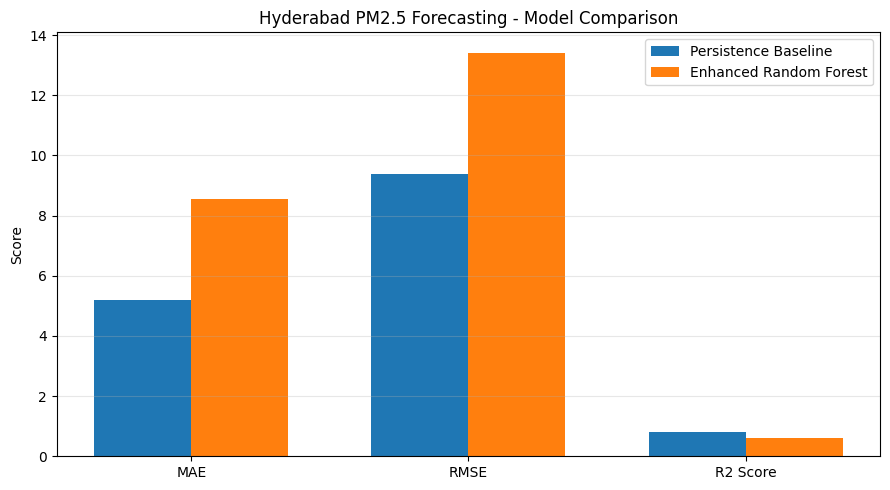

In [25]:

# Step 19: Compare model performance visually

import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE", "RMSE", "R2 Score"]
baseline = [5.203, 9.391, 0.801]
random_forest = [8.535, 13.420, 0.593]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, baseline, width, label="Persistence Baseline")
plt.bar(x + width/2, random_forest, width, label="Enhanced Random Forest")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Hyderabad PM2.5 Forecasting - Model Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Visualization of Model Performance Comparison

The bar chart compares the Persistence Baseline and Enhanced Random Forest models using MAE, RMSE, and R² Score.

- **MAE:** The Persistence Baseline has a lower error (5.203) than the Enhanced Random Forest (8.535).
- **RMSE:** The Persistence Baseline achieves a lower RMSE (9.391) than the Enhanced Random Forest (13.420), indicating fewer large prediction errors overall.
- **R² Score:** The Persistence Baseline achieves a higher R² score (0.801) than the Enhanced Random Forest (0.593), indicating that it explains more of the variation in the test data.

**Conclusion:** The visualization shows that the Persistence Baseline outperforms the Enhanced Random Forest across all three metrics in this experiment. This highlights the importance of comparing machine-learning models against simple baseline methods before drawing conclusions about their effectiveness.

### Step 20: Actual vs Predicted — Both Models

In this step, we visualize the actual PM2.5 concentrations alongside predictions from the Persistence Baseline and Enhanced Random Forest models.

- **Actual PM2.5:** Represents the observed pollution concentrations in the test dataset.
- **Persistence Baseline:** Uses the current hour's PM2.5 reading to predict the next hour.
- **Enhanced Random Forest:** Uses historical PM2.5 readings and rolling statistical features to generate predictions.
- **First 200 observations:** Focuses on a subset of the valid test observations for easier visual interpretation.
- **Prediction comparison:** Helps identify which model follows the actual pollution trend more closely and how each responds to sudden changes.

This visualization complements the numerical evaluation metrics and helps explain the strengths and limitations of both forecasting approaches.

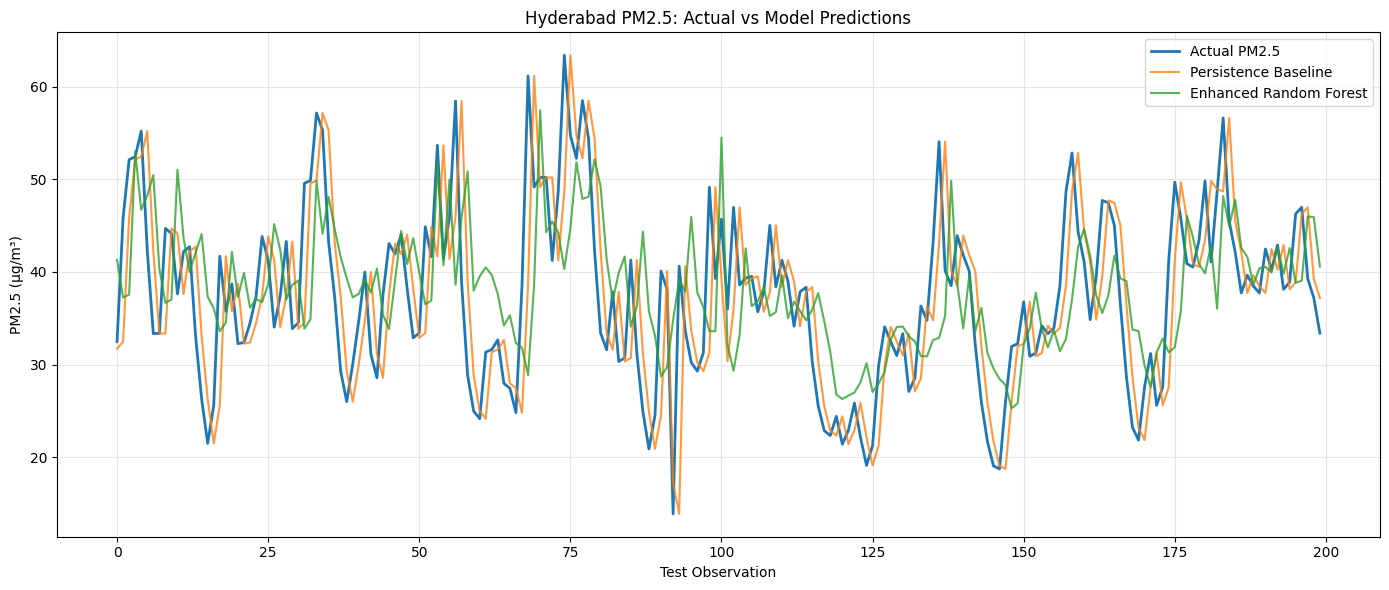

In [26]:

# Step 20: Actual vs Predicted - Both Models

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

actual = comparison_data["Actual"].values[:200]
baseline_pred = comparison_data["Baseline"].values[:200]
rf_pred = comparison_data["Random_Forest"].values[:200]

plt.plot(actual, label="Actual PM2.5", linewidth=2)
plt.plot(baseline_pred, label="Persistence Baseline", alpha=0.8)
plt.plot(rf_pred, label="Enhanced Random Forest", alpha=0.8)

plt.title("Hyderabad PM2.5: Actual vs Model Predictions")
plt.xlabel("Test Observation")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Actual vs Predicted PM2.5 Concentrations

This line chart compares the actual PM2.5 concentrations with predictions from the Persistence Baseline and Enhanced Random Forest models across 200 test observations.

- **Actual PM2.5:** Represents the observed pollution concentrations.
- **Persistence Baseline:** Predicts the next-hour concentration using the current PM2.5 measurement.
- **Enhanced Random Forest:** Uses multiple features to estimate the next-hour PM2.5 concentration.

The Persistence Baseline closely follows the actual measurements throughout much of the plotted period. The Enhanced Random Forest also captures several fluctuations, but its predictions sometimes differ from the observed values, particularly around rapid changes in pollution levels.

**Conclusion:** The visualization supports the quantitative evaluation, in which the Persistence Baseline outperformed the Enhanced Random Forest across MAE, RMSE, and R² Score. The results suggest that current PM2.5 measurements provide a useful reference for short-term forecasting, while further model development may be needed to improve predictions during sudden fluctuations.